# 3. Préparation des données

Ce notebook vérifie les séries préparées par `moteur.series`, à savoir la pluie et l'évapotranspiration de référence FAO 56, moyennées sur les neuf points de chaque lieu.

In [1]:
import sys
sys.path.insert(0, "..")
import matplotlib.pyplot as plt
from donnees.config import charger
from moteur.series import series_lieux
config = charger()
series = series_lieux(config)
noms = {l["id"]: l["nom"] for l in config["lieux"]}

In [2]:
import math
for lieu, s in series.items():
    valeurs = s["et0"]
    print(noms[lieu], "jours", len(valeurs), "manquants", sum(math.isnan(v) for v in valeurs),
          "minimum", round(min(valeurs), 2), "maximum", round(max(valeurs), 2), "moyenne", round(sum(valeurs) / len(valeurs), 2), "mm par jour")

Korhogo jours 8766 manquants 0 minimum 1.37 maximum 10.32 moyenne 5.19 mm par jour
Bouaké jours 8766 manquants 0 minimum 1.31 maximum 9.47 moyenne 4.21 mm par jour


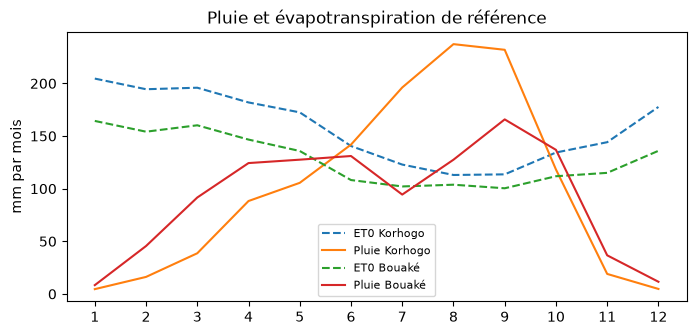

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for lieu, s in series.items():
    annees = len({j.year for j in s["jours"]})
    et0, pluie = [0.0] * 12, [0.0] * 12
    for jour, e, p in zip(s["jours"], s["et0"], s["pluie"]):
        et0[jour.month - 1] += e / annees
        pluie[jour.month - 1] += p / annees
    ax.plot(range(1, 13), et0, linestyle="--", label=f"ET0 {noms[lieu]}")
    ax.plot(range(1, 13), pluie, label=f"Pluie {noms[lieu]}")
ax.set_ylabel("mm par mois"); ax.set_xticks(range(1, 13)); ax.set_title("Pluie et évapotranspiration de référence"); ax.legend(fontsize=8); plt.show()

**Constat**

L'évapotranspiration de référence reste positive et dans des valeurs plausibles pour une savane tropicale. Elle dépasse la pluie en saison sèche et lui est inférieure au cœur de la saison des pluies.

**Analyse**

Le calcul est testé contre l'exemple 18 de FAO 56 dans `tests/test_moteur.py`. Il suppose un flux de chaleur du sol nul à l'échelle journalière, comme le recommande FAO 56.